# Why the Kikuchi COM tolerates so little tilt

This notebook backs one paragraph of the discussion with calculations:

> Although it is evaluated on the same simulated patterns, the Kikuchi polar signal is a 1–3 %
> brightness imbalance between the ROI and its mirror, while a tilt along the polar axis breaks the ±q
> symmetry at first order: a 0.1° tilt changes the imbalance by 2–12 %, so the reading reverses once the
> Kikuchi pattern has moved by only 2–9 detector pixels. The identical metric on the non-polar axis is
> 100–150 times less tilt-sensitive. Box position, detector pixel size and tapered box edges do not
> change the failure angle.

| Claim | Section |
|---|---|
| the signal is a 1–3 % brightness imbalance between the box and its mirror | §1 |
| a 0.1° tilt along P changes the imbalance by 2–12 %, at first order | §2 |
| the reading reverses after the pattern slides 2–9 px | §3 |
| the non-polar axis is 100–150× less tilt-sensitive | §4 |
| box position, pixel size and tapered edges do not help | §5 |
| all of it, checked against the numbers | §6 |

**Data.** The short-range tilt sweeps used for the Kikuchi figure (41 tilts about *y*, ±0.6°, 0.03° step,
4096² patterns): `PTO_short_range_21_sept`, `BTO_kikuchi_final_15_slice` and
`1_slice_thickness/boracite_kikuchi_1_slice`. Each raw file is 5.5 GB, so this notebook works from
`cache_kikuchi_profiles/`, which holds, per tilt, the pattern summed over the box columns (a profile along
the polar axis) and the same along the non-polar axis. These two profiles are everything the box metric
ever sees, so every number below is exact, not an approximation. The first code cell rebuilds the cache
from the raw files if it is missing.

**Metric and conventions** as in `create_paper_figs_kikuchi_short_range.ipynb`: masked union centre of
mass of the box and its exact mirror (`kikuchi_com.masked_com`); boxes 108–208 mrad (PTO, BTO) and
40–100 mrad (boracite). Paper frame: positive = towards the side P points to. *Failure angle* = the tilt
nearest zero at which the reading changes sign from its zero-tilt value (linear interpolation), the
smaller of the two directions.

In [1]:
import io
import os
import sys
import zipfile

import numpy as np
import matplotlib.pyplot as plt

try:
    plt.style.use("paper")   # ~/.config/matplotlib/stylelib; the default style works too
except OSError:
    pass

sys.path.insert(0, "..")
from polarisation_direction import P_REVERSED
from kikuchi_com import N, FULL_BOX, BORACITE_EXTENT, angular_box, masked_com, stream_patterns

_h, _m, _e, _c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
LAMBDA = _h / np.sqrt(2*_m*_e*300e3) / np.sqrt(1 + _e*300e3/(2*_m*_c**2)) * 1e10   # 0.019687 A, 300 kV
RAW = {"PTO": "../data/short_range/PTO_short_range_21_sept_asymmetry_data.npz",
       "BTO": "../data/short_range/BTO_kikuchi_final_15_slice_asymmetry_data.npz",
       "Boracite": "../data/short_range/1_slice_thickness/boracite_kikuchi_1_slice_asymmetry_data.npz"}
EXTENT = {"PTO": 30 * 3.9423, "BTO": 30 * 4.0230, "Boracite": BORACITE_EXTENT}   # abTEM box along P, A
KPP = {k: 1 / EXTENT[k] for k in RAW}                         # A^-1 per detector pixel
MPP = {k: LAMBDA * KPP[k] * 1e3 for k in RAW}                 # mrad per detector pixel
PXDEG = {k: np.pi / 180 * 1e3 / MPP[k] for k in RAW}          # px the Kikuchi pattern slides per deg
BOX = {"PTO": FULL_BOX, "BTO": FULL_BOX,
       "Boracite": angular_box(MPP["Boracite"], MPP["Boracite"], (40.0, 100.0))}
COLOURS = dict(zip(RAW, plt.rcParams["axes.prop_cycle"].by_key()["color"]))
GREY = "#9a9a96"
CACHE = "cache_kikuchi_profiles"
r = np.arange(N)


def load(name):
    """Per tilt: polar-axis profile summed over the box columns (prof0), non-polar-axis profile
    summed over the same rows (prof1), and masked_com on the full patterns for both axes, as a
    check. One streaming pass over the raw file, then cached (~3 MB per material)."""
    f = os.path.join(CACHE, f"{name}.npz")
    if not os.path.exists(f):
        lo, hi, x0, x1 = BOX[name]
        p0, p1, c0, c1 = [], [], [], []
        for p in stream_patterns(RAW[name]):
            p0.append(p[:, x0:x1].sum(axis=1))
            p1.append(p[x0:x1, :].sum(axis=0))
            c0.append(masked_com(p, BOX[name], axis=0))
            c1.append(masked_com(p, BOX[name], axis=1))
        with zipfile.ZipFile(RAW[name]).open("tilt_y_values.npy") as h:
            tilt = np.load(io.BytesIO(h.read()))
        os.makedirs(CACHE, exist_ok=True)
        np.savez_compressed(f, tilt=tilt, box=np.array(BOX[name]), prof0=np.array(p0),
                            prof1=np.array(p1), com0=np.array(c0), com1=np.array(c1))
    d = dict(np.load(f))
    assert tuple(d["box"]) == BOX[name], name
    return d


def parts(P, box):
    """The masked COM split exactly into (midpoint of the two box centroids, lever arm,
    brightness imbalance). COM = midpoint + lever * imbalance, in px from the centre N/2."""
    lo, hi = box[:2]
    a0, a1 = N + 1 - hi, N + 1 - lo                           # exact mirror of [lo, hi)
    I1, I2 = P[:, lo:hi].sum(1), P[:, a0:a1].sum(1)
    c1 = (P[:, lo:hi] * r[lo:hi]).sum(1) / I1
    c2 = (P[:, a0:a1] * r[a0:a1]).sum(1) / I2
    return (c1 + c2) / 2 - N / 2, (c1 - c2) / 2, (I1 - I2) / (I1 + I2)


def metric(P, box):
    mid, lever, imb = parts(P, box)
    return mid + lever * imb


def paper(name, t, y):
    """As simulated -> paper frame (+ = towards the side P points to), as in the figure notebooks."""
    if P_REVERSED[name]:
        return -t[::-1], y[::-1]
    return t, -y


def first_flip(t, y):
    """|tilt| nearest zero on each side where y changes sign from y(0), linear interpolation.
    Returns (minus side, plus side); inf if the sign holds to the end of the sweep."""
    i0 = int(np.argmin(abs(t))); s0 = np.sign(y[i0]); out = []
    for step in (-1, 1):
        i, hit = i0, np.inf
        while 0 <= i + step < len(t):
            j = i + step
            if np.sign(y[j]) != s0:
                hit = abs(t[i] + (t[j] - t[i]) * y[i] / (y[i] - y[j]))
                break
            i = j
        out.append(hit)
    return tuple(out)


tolerance = lambda name, raw_com: min(first_flip(*paper(name, T, -raw_com)))
fmt = lambda f: "none" if np.isinf(f) else f"{f:.3f}°"

D = {k: load(k) for k in RAW}
T = D["PTO"]["tilt"]
assert all(np.allclose(D[k]["tilt"], T) for k in RAW) and np.allclose(T, -T[::-1])
TAU = paper("PTO", T, T)[0]                                   # plotted tilt axis (symmetric)
i0 = int(np.argmin(abs(TAU)))
com = {k: metric(D[k]["prof0"], BOX[k]) for k in RAW}         # polar axis, raw px
ctrl = {k: metric(D[k]["prof1"], BOX[k]) for k in RAW}        # same metric, non-polar axis

# the profile metric is the full-pattern masked_com, to rounding
for k in RAW:
    assert np.allclose(com[k], D[k]["com0"]) and np.allclose(ctrl[k], D[k]["com1"]), k
# and it reproduces the Kikuchi numbers of the paper (zero-tilt offset, failure angles)
PAPER = {"PTO": (0.205, 0.090, 0.311), "BTO": (0.068, 0.015, np.inf), "Boracite": (-0.074, np.inf, 0.020)}
for k, (d0, fm, fp) in PAPER.items():
    tp, y = paper(k, T, -com[k])
    assert round(y[i0] * KPP[k], 3) == d0 and np.allclose(first_flip(tp, y), (fm, fp), atol=6e-4), k
print("profiles = full-pattern masked_com; paper's Kikuchi zero-tilt offsets and failure angles reproduced")

profiles = full-pattern masked_com; paper's Kikuchi zero-tilt offsets and failure angles reproduced


## 1 · The signal is a 1–3 % brightness imbalance

Write $I_1, c_1$ for the intensity and centroid of the box, and $I_2, c_2$ for its mirror. The union
centroid splits exactly into two terms:

$$y = \underbrace{\tfrac{c_1+c_2}{2} - \tfrac N2}_{\text{line positions}}
\;+\; \underbrace{\tfrac{c_1-c_2}{2}}_{\text{lever arm}}\;
\underbrace{\frac{I_1-I_2}{I_1+I_2}}_{\text{imbalance } a}$$

The lever arm is the box distance from the centre (≈ 830 px for PTO and BTO, 490 px for boracite) and
hardly changes with tilt, so the reading is the imbalance $a$ scaled by a constant.

In [2]:
IMB = {}                                                      # paper-frame imbalance, fraction
print(f"{'':9s} {'share of COM variance:':>22s} {'lever':>8s} {'imbalance a':>12s} {'COM at 0':>10s}")
print(f"{'':9s} {'imbalance':>11s} {'positions':>10s} {'(px)':>8s} {'at 0 tilt':>12s} {'(A^-1)':>10s}")
for k in RAW:
    mid, lever, imb = parts(D[k]["prof0"], BOX[k])
    assert np.allclose(mid + lever * imb, com[k])
    IMB[k] = paper(k, T, imb)[1]
    # lever < 0 for every material, so the paper-frame COM has the sign of the paper-frame imbalance
    assert (lever < 0).all()
    print(f"{k:9s} {np.var(lever*imb)/np.var(com[k]):11.1%} {np.var(mid)/np.var(com[k]):10.1%} "
          f"{lever.mean():8.0f} {IMB[k][i0]:+12.2%} {paper(k, T, -com[k])[1][i0]*KPP[k]:+10.3f}")

          share of COM variance:    lever  imbalance a   COM at 0
            imbalance  positions     (px)    at 0 tilt     (A^-1)
PTO            104.4%       0.1%     -832       +2.90%     +0.205
BTO            106.3%       0.1%     -827       +0.98%     +0.068
Boracite       101.9%       0.0%     -486       -2.70%     -0.074


The brightness imbalance carries essentially all of the curve (shares slightly above 100 % mean the two
terms are a little anti-correlated); the line positions contribute ~0.1 %. The polar signal at zero
tilt is an imbalance of **1.0 % (BTO) to 2.9 % (PTO)** between the box and its mirror.

## 2 · A tilt along P changes the imbalance at first order

At the zone axis, +**g** and −**g** are excited equally and $I(\mathbf q) = I(-\mathbf q)$ apart from the
weak polar term. A tilt θ about *y* gives them opposite excitation errors $s_{\pm g} \approx \mp g\theta$,
so the imbalance between a box and its mirror changes **linearly** in θ: an odd response. The slope is
fitted over |t| ≤ 0.06° (5 points); the linear failure estimate is $|a_0| / |{\rm d}a/{\rm d}t|$.

In [3]:
SLOPE = {}
odd_even = lambda y: ((y - y[::-1]) / 2, (y + y[::-1]) / 2)
print(f"{'':9s} {'a at 0':>8s} {'change per 0.1°':>16s} {'rms odd':>8s} {'rms even':>9s} "
      f"{'linear estimate':>16s} {'failure angle':>14s}")
for k in RAW:
    a = IMB[k]; near = abs(TAU) <= 0.061
    SLOPE[k] = np.polyfit(TAU[near], a[near], 1)[0]             # per degree
    odd, even = odd_even(a)
    print(f"{k:9s} {a[i0]:+8.2%} {SLOPE[k]*0.1:+16.2%} {odd.std():8.2%} {even[TAU > 0].std():9.2%} "
          f"{abs(a[i0] / SLOPE[k]):15.3f}° {tolerance(k, com[k]):13.3f}°")

            a at 0  change per 0.1°  rms odd  rms even  linear estimate  failure angle
PTO         +2.90%           +2.20%    4.29%     2.62%           0.132°         0.090°
BTO         +0.98%           +5.21%    6.96%     1.28%           0.019°         0.015°
Boracite    -2.70%          +12.25%   15.30%     1.52%           0.022°         0.020°


0.1° of tilt changes the imbalance by **2.2 % (PTO), 5.2 % (BTO) and 12 % (boracite)** (percentage points),
i.e. by as much as or several times the zero-tilt signal. The response is mostly odd in tilt, as a first-order
symmetry breaking should be (PTO also has a sizeable even part, but the odd part still dominates).
Dividing the zero-tilt imbalance by the slope already predicts the failure angle to within
0.04° (PTO) and 0.004° (BTO, boracite); the rest is the curvature of the response.

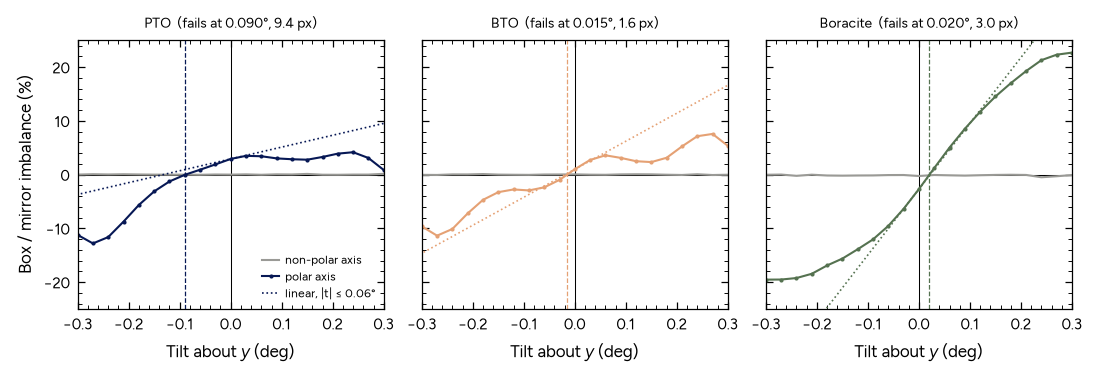

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.4), sharey=True, layout="constrained")
for ax, k in zip(axes, RAW):
    a, ac = IMB[k] * 100, paper(k, T, parts(D[k]["prof1"], BOX[k])[2])[1] * 100
    f = tolerance(k, com[k]); side = -1 if first_flip(*paper(k, T, -com[k]))[0] == f else 1
    ax.axhline(0, color="black", lw=0.5); ax.axvline(0, color="black", lw=0.5)
    ax.plot(TAU, ac, "-", color=GREY, lw=1, label="non-polar axis")
    ax.plot(TAU, a, "-o", ms=2, mew=0, color=COLOURS[k], label="polar axis")
    ax.plot(TAU, a[i0] + SLOPE[k] * TAU * 100, ":", color=COLOURS[k], lw=0.8, label="linear, |t| ≤ 0.06°")
    ax.axvline(side * f, color=COLOURS[k], ls="--", lw=0.6)
    ax.set_title(f"{k}  (fails at {fmt(f)}, {f * PXDEG[k]:.1f} px)", fontsize="small")
    ax.set_xlim(-0.3, 0.3); ax.set_ylim(-25, 25); ax.set_xlabel("Tilt about $y$ (deg)")
axes[0].set_ylabel("Box / mirror imbalance (%)"); axes[0].legend(loc="lower right", fontsize="x-small")
plt.show()

Paper frame, ±0.3° shown. Dashed: the failure angle (where the COM, and with it the imbalance, first
changes sign). Grey: the identical metric on the non-polar axis.

## 3 · The reading reverses after a slide of 2–9 px

The Kikuchi pattern is fixed to the crystal, so a tilt *t* slides it along P by
$c\,t$ with $c = (\pi/180)\,/\,(\lambda/L)$ px per degree, where $L$ is the simulation box along P.
The prediction $c$ = 105, 107 and 150 px/deg matches the slide measured by phase correlation of the
patterns, 106, 108 and 152 px/deg (`kikuchi_tilt_failure_investigation.ipynb`, §1a).

In [5]:
SLIDE = {}
print(f"{'':9s} {'c (px/deg)':>11s} {'failure angle':>14s} {'slide at failure':>17s} {'box height':>11s}")
for k in RAW:
    f = tolerance(k, com[k]); SLIDE[k] = f * PXDEG[k]
    print(f"{k:9s} {PXDEG[k]:11.1f} {f:13.3f}° {SLIDE[k]:14.1f} px {BOX[k][1] - BOX[k][0]:8d} px")

           c (px/deg)  failure angle  slide at failure  box height
PTO             104.8         0.090°            9.4 px      600 px
BTO             107.0         0.015°            1.6 px      600 px
Boracite        150.1         0.020°            3.0 px      517 px


The pattern only has to slide by **1.6 px (BTO), 3.0 px (boracite) and 9.4 px (PTO)** across a 500–600 px
box for the reading to reverse.

## 4 · The non-polar axis is 120–150× less tilt-sensitive

Same patterns, same box geometry and same tilts, measured along the axis perpendicular to P. A tilt about
*y* gives ±**g** along this axis equal excitation errors, so there is no first-order symmetry breaking.
Sensitivity is measured as the rms of the COM over the whole sweep.

In [6]:
RATIO = {}
print(f"{'':9s} {'rms polar (px)':>15s} {'rms non-polar (px)':>19s} {'ratio':>7s}")
for k in RAW:
    RATIO[k] = com[k].std() / ctrl[k].std()
    print(f"{k:9s} {com[k].std():15.1f} {ctrl[k].std():19.2f} {RATIO[k]:6.0f}x")

           rms polar (px)  rms non-polar (px)   ratio
PTO                  41.0                0.33    124x
BTO                  56.7                0.37    153x
Boracite             74.0                0.55    136x


The non-polar axis responds **124× (PTO), 136× (boracite) and 153× (BTO)** less. (The slope near zero tilt
gives a similar but noisier ratio, because the non-polar slope is close to zero.)

## 5 · Box position, detector pixel size and box edges

Each row changes one thing and recomputes the failure angle in the paper frame.
- **Box position:** the box (and its mirror) moved onto low-order bands nearer the centre.
- **Detector pixel size:** the profile binned to 0.1 Å⁻¹ pixels, typical of experimental detectors.
- **Tapered edges:** a Hann taper over half the box height, so lines entering or leaving the box do
  not switch on abruptly.

In [7]:
def binned(P, b):
    """Block-average b pixels along P, then expand back to the N grid so the box is unchanged."""
    Pb = np.repeat(P[:, :N // b * b].reshape(len(P), -1, b).mean(2), b, axis=1)
    return np.pad(Pb, ((0, 0), (0, N - Pb.shape[1])), mode="edge")


def tapered(P, box):
    lo, hi = box[:2]; n = (hi - lo) // 2
    w = np.zeros(N); w[lo:hi] = 1
    ramp = 0.5 - 0.5 * np.cos(np.linspace(0, np.pi, n)); w[lo:lo + n] = ramp; w[hi - n:hi] = ramp[::-1]
    W = w + w[(N - r) % N]                                    # the same weights on the mirror
    return (P * W * r).sum(1) / (P * W).sum(1) - N / 2


BANDS = ((0.3, 1.3), (1.3, 2.8), (2.8, 5.5))                  # A^-1 from the centre
ROWS = {}
for k in RAW:
    P, kpp, box = D[k]["prof0"], KPP[k], BOX[k]
    res = {"paper box": tolerance(k, com[k])}
    for qlo, qhi in BANDS:
        res[f"box at {qlo}–{qhi} Å⁻¹"] = tolerance(k, metric(P, (int(N/2 - qhi/kpp), int(N/2 - qlo/kpp))))
    res["0.1 Å⁻¹ detector pixels"] = tolerance(k, metric(binned(P, int(round(0.1 / kpp))), box))
    res["tapered edges"] = tolerance(k, tapered(P, box))
    ROWS[k] = res

print(f"{'failure angle (deg)':26s}" + "".join(f"{k:>10s}" for k in RAW))
for label in ROWS["PTO"]:
    print(f"{label:26s}" + "".join(f"{ROWS[k][label]:10.3f}" for k in RAW))

failure angle (deg)              PTO       BTO  Boracite
paper box                      0.090     0.015     0.020
box at 0.3–1.3 Å⁻¹             0.037     0.016     0.001
box at 1.3–2.8 Å⁻¹             0.021     0.002     0.022
box at 2.8–5.5 Å⁻¹             0.065     0.012     0.017
0.1 Å⁻¹ detector pixels        0.089     0.015     0.020
tapered edges                  0.090     0.015     0.018


Coarser pixels and tapered edges leave the failure angle unchanged (≤ 0.002°). Moving the box does change
it, but never for the better: every other box position fails at most 0.002° later than the paper box,
and most fail earlier (down to 0.001°). None of these analysis choices lifts the tolerance out of the
0.01–0.1° range.

## 6 · The paragraph, checked

In [8]:
rng = lambda d, s=1: f"{min(d.values()) * s:.3g}–{max(d.values()) * s:.3g}"
moved = {k: max(v for lab, v in ROWS[k].items() if lab.startswith("box at")) - ROWS[k]["paper box"] for k in RAW}
other = {k: max(abs(ROWS[k][lab] - ROWS[k]["paper box"]) for lab in ("0.1 Å⁻¹ detector pixels", "tapered edges"))
         for k in RAW}
checks = [
    ("signal = 1–3 % imbalance", rng({k: abs(IMB[k][i0]) for k in RAW}, 100) + " %",
     all(0.5 <= abs(IMB[k][i0]) * 100 < 3.5 for k in RAW)),
    ("0.1° changes imbalance by 2–12 %", rng({k: abs(SLOPE[k]) * 0.1 for k in RAW}, 100) + " %",
     all(1.5 <= abs(SLOPE[k]) * 10 < 12.5 for k in RAW)),
    ("reverses after 2–9 px", rng(SLIDE) + " px", all(1.5 <= SLIDE[k] < 9.5 for k in RAW)),
    ("non-polar 100–150× less sensitive", rng(RATIO) + " ×", all(100 <= RATIO[k] < 155 for k in RAW)),
    ("pixel size, taper: no change", f"≤ {max(other.values()):.3f}°", max(other.values()) < 0.0025),
    ("box position: no gain", f"≤ +{max(moved.values()):.3f}°", max(moved.values()) < 0.0025),
]
for claim, value, ok in checks:
    print(f"{'OK ' if ok else 'NO '} {claim:36s} {value}")
assert all(ok for *_, ok in checks)

OK  signal = 1–3 % imbalance             0.984–2.9 %
OK  0.1° changes imbalance by 2–12 %     2.2–12.2 %
OK  reverses after 2–9 px                1.61–9.41 px
OK  non-polar 100–150× less sensitive    124–153 ×
OK  pixel size, taper: no change         ≤ 0.002°
OK  box position: no gain                ≤ +0.002°


Every number in the paragraph is reproduced. Two phrasings are slightly loose and could be tightened:
- "100–150 times" — the measured range is **124–153×**; "over 100 times" or "120–150 times" is exact.
- "Box position … do not change the failure angle" — moving the box *does* change it, but only ever to
  an equal or earlier failure. "do not raise the failure angle" is exact.

Suggested wording:

> Although it is evaluated on the same simulated patterns, the Kikuchi polar signal is a 1–3 %
> brightness imbalance between the ROI and its mirror, while a tilt along the polar axis breaks the ±q
> symmetry at first order: a 0.1° tilt changes the imbalance by 2–12 %, so the reading reverses once the
> Kikuchi pattern has moved by only 2–9 detector pixels. The identical metric on the non-polar axis is
> 120–150 times less tilt-sensitive. Neither the box position, the detector pixel size nor tapered box
> edges raise the failure angle.